# Explainable Brain Tumor Classification (EfficientNetB0 + Grad-CAM)
Run the cells from top to bottom. If `TRAIN = False` (Step 3) the notebook loads your already-saved model, so no re-training is needed.

## Step 1: Imports

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Step 2: Load the dataset

In [2]:
train_dir = "DATASETS/Training"
test_dir  = "DATASETS/Testing"
IMG_SIZE  = (224, 224)
BATCH_SIZE = 32

# NOTE: images stay in 0-255 range. EfficientNetB0 rescales them itself, so do NOT divide by 255.
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.2, subset="training", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.2, subset="validation", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir, shuffle=False, image_size=IMG_SIZE, batch_size=BATCH_SIZE)

class_names = train_dataset.class_names
print("Classes:", class_names)

Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


## Step 3: Train the model (optional)
Keep `TRAIN = False` to skip training and use the saved model. Set it to `True` only if you want to train again (about 10 minutes).

In [3]:
TRAIN = False
MODEL_PATH = "MODELS/brain_tumor_efficientnetb0_finetuned.keras"
if TRAIN:
    from tensorflow.keras.applications import EfficientNetB0
    from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
    from tensorflow.keras.models import Model
    from tensorflow.keras.optimizers import Adam

    base_model = EfficientNetB0(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False

    x = GlobalAveragePooling2D()(base_model.output)
    x = Dropout(0.3)(x)
    outputs = Dense(4, activation="softmax")(x)
    model = Model(inputs=base_model.input, outputs=outputs)

    model.compile(optimizer=Adam(learning_rate=0.0001),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

    history = model.fit(train_dataset, validation_data=val_dataset, epochs=10)
    os.makedirs("MODELS", exist_ok=True)
    model.save(MODEL_PATH)
    print("Model saved")

## Step 4: Load the saved model and test it

In [4]:
model = tf.keras.models.load_model(MODEL_PATH)
test_loss, test_acc = model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:.4f}")

50/50 ━━━━━━━━━━━━━━━━━━━━ 117s 2s/step - accuracy: 0.8481 - loss: 0.4489
Test accuracy: 0.8481


## Step 5: Confusion matrix and report

50/50 ━━━━━━━━━━━━━━━━━━━━ 50s 717ms/step
              precision    recall  f1-score   support

      glioma       0.92      0.66      0.77       400
  meningioma       0.73      0.80      0.77       400
     notumor       0.86      0.99      0.92       400
   pituitary       0.91      0.94      0.93       400

    accuracy                           0.85      1600
   macro avg       0.86      0.85      0.84      1600
weighted avg       0.86      0.85      0.84      1600



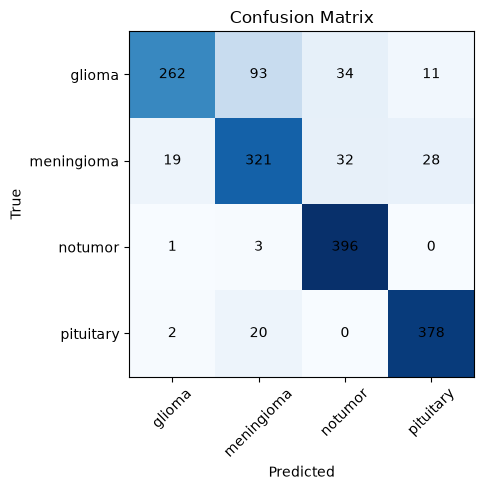

In [5]:
y_true = np.concatenate([y.numpy() for _, y in test_dataset])
y_pred = np.argmax(model.predict(test_dataset), axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xticks(range(4), class_names, rotation=45)
plt.yticks(range(4), class_names)
for i in range(4):
    for j in range(4):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
os.makedirs("RESULTS", exist_ok=True)
plt.savefig("RESULTS/confusion_matrix.png", dpi=150)
plt.show()

## Step 6: Grad-CAM functions

In [6]:
LAST_CONV_LAYER = "block4c_add"

def load_image(path):
    # Returns (batch ready for the model, original RGB image). Values stay 0-255.
    bgr = cv2.imread(path)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    small = cv2.resize(rgb, IMG_SIZE).astype("float32")
    return np.expand_dims(small, axis=0), rgb

def make_gradcam_heatmap(img_batch, model, layer_name=LAST_CONV_LAYER):
    grad_model = tf.keras.Model(model.inputs,
                                [model.get_layer(layer_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_batch, training=False)
        pred_index = tf.argmax(preds[0])
        class_score = preds[:, pred_index]
    grads = tape.gradient(class_score, conv_out)
    pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.reduce_sum(conv_out[0] * pooled, axis=-1)
    cam = tf.maximum(cam, 0)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), int(pred_index), preds.numpy()[0]

def make_overlay(rgb_image, cam, alpha=0.4):
    cam_resized = cv2.resize(cam, (rgb_image.shape[1], rgb_image.shape[0]))
    colored = cv2.applyColorMap(np.uint8(255 * cam_resized), cv2.COLORMAP_JET)
    colored = cv2.cvtColor(colored, cv2.COLOR_BGR2RGB)
    return cv2.addWeighted(rgb_image, 1 - alpha, colored, alpha, 0), colored

## Step 7: Grad-CAM on one image

Pixel range: 0.0 to 255.0


c:\Users\AFRAH\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer_1']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


Prediction: pituitary (39.5%)


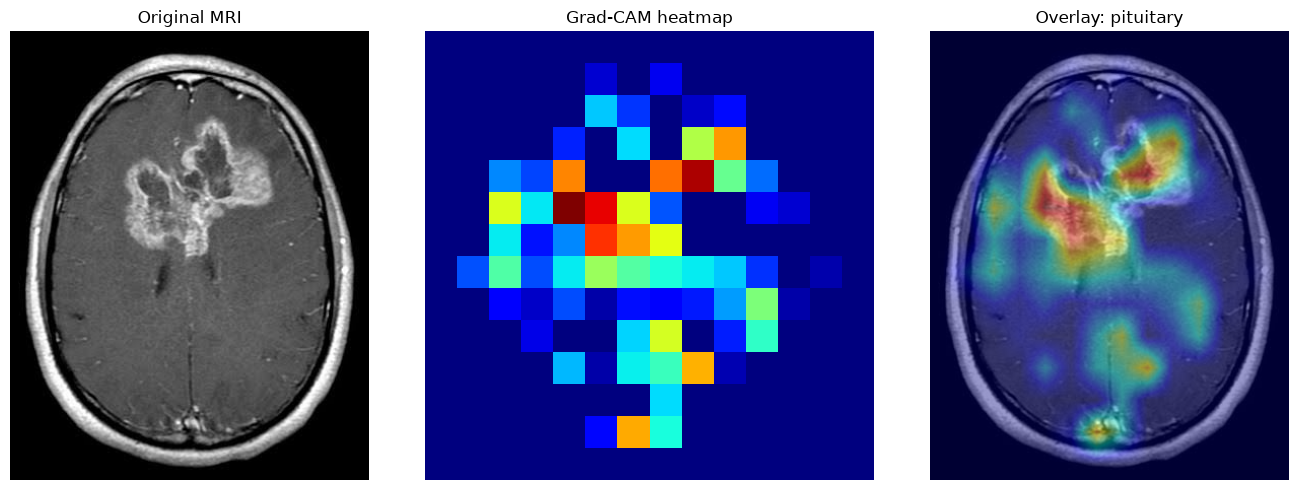

In [7]:
img_path = "SAMPLE_IMAGES/test.jpg"

img_batch, rgb = load_image(img_path)
print("Pixel range:", img_batch.min(), "to", img_batch.max())   # max should be about 255

cam, pred_idx, probs = make_gradcam_heatmap(img_batch, model)
overlay, colored = make_overlay(rgb, cam)

print(f"Prediction: {class_names[pred_idx]} ({probs[pred_idx]*100:.1f}%)")

fig, ax = plt.subplots(1, 3, figsize=(14, 5))
ax[0].imshow(rgb);      ax[0].set_title("Original MRI")
ax[1].imshow(cam, cmap="jet"); ax[1].set_title("Grad-CAM heatmap")
ax[2].imshow(overlay);  ax[2].set_title(f"Overlay: {class_names[pred_idx]}")
for a in ax: a.axis("off")
plt.tight_layout()
plt.savefig("RESULTS/gradcam_sample.png", dpi=150)
plt.show()

## Step 8: One Grad-CAM example per class (for your report)

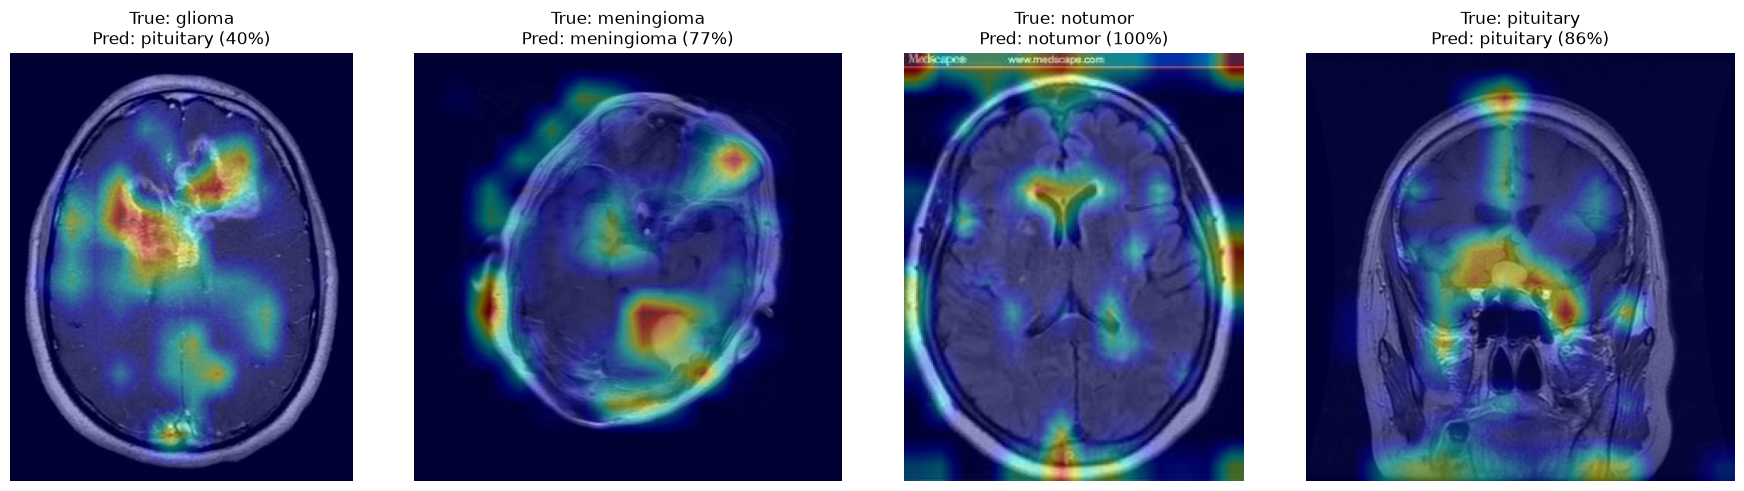

In [8]:
fig, ax = plt.subplots(1, 4, figsize=(18, 5))
for k, cls in enumerate(class_names):
    folder = os.path.join(test_dir, cls)
    path = os.path.join(folder, sorted(os.listdir(folder))[0])
    batch, rgb_img = load_image(path)
    cam, idx, probs = make_gradcam_heatmap(batch, model)
    overlay, _ = make_overlay(rgb_img, cam)
    ax[k].imshow(overlay)
    ax[k].set_title(f"True: {cls}\nPred: {class_names[idx]} ({probs[idx]*100:.0f}%)")
    ax[k].axis("off")
plt.tight_layout()
plt.savefig("RESULTS/gradcam_all_classes.png", dpi=150)
plt.show()

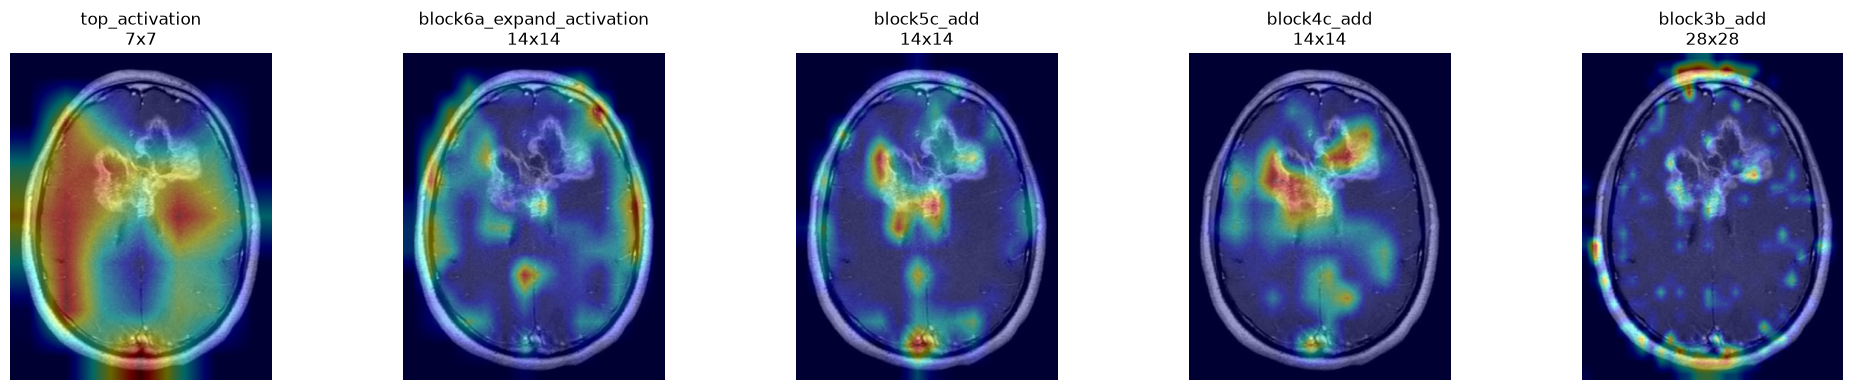

In [9]:
layers_to_try = ["top_activation", "block6a_expand_activation",
                 "block5c_add", "block4c_add", "block3b_add"]

img_batch, rgb = load_image("SAMPLE_IMAGES/test.jpg")

fig, ax = plt.subplots(1, len(layers_to_try), figsize=(20, 4))
for k, name in enumerate(layers_to_try):
    cam, idx, probs = make_gradcam_heatmap(img_batch, model, layer_name=name)
    overlay, _ = make_overlay(rgb, cam)
    ax[k].imshow(overlay)
    ax[k].set_title(f"{name}\n{cam.shape[0]}x{cam.shape[1]}")
    ax[k].axis("off")
plt.tight_layout()
plt.show()

In [10]:
FINE_TUNE = False   # set True only to fine-tune again (10-25 min)

if FINE_TUNE:
    for layer in model.layers:
        layer.trainable = False
    for layer in model.layers[-30:]:
        if not isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = True
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])
    history = model.fit(train_dataset, validation_data=val_dataset, epochs=5)
    model.save("MODELS/brain_tumor_efficientnetb0_finetuned.keras")
    print("Saved fine-tuned model")
    model.evaluate(test_dataset)

In [11]:
   old = tf.keras.models.load_model("MODELS/brain_tumor_efficientnetb0.keras")
   new = tf.keras.models.load_model("MODELS/brain_tumor_efficientnetb0_finetuned.keras")
   print("old model [loss, accuracy]:", old.evaluate(test_dataset, verbose=0))
   print("new model [loss, accuracy]:", new.evaluate(test_dataset, verbose=0))

old model [loss, accuracy]: [0.5448513031005859, 0.8031250238418579]
new model [loss, accuracy]: [0.4488506019115448, 0.8481249809265137]


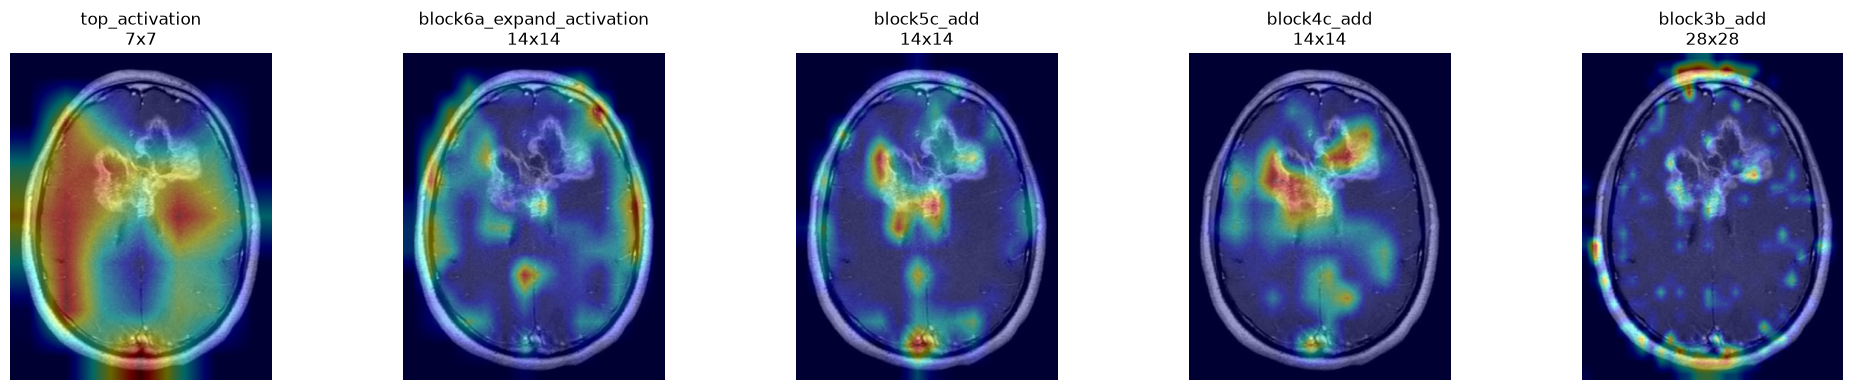

In [12]:
layers_to_try = ["top_activation", "block6a_expand_activation",
                 "block5c_add", "block4c_add", "block3b_add"]

img_batch, rgb = load_image("SAMPLE_IMAGES/test.jpg")

fig, ax = plt.subplots(1, len(layers_to_try), figsize=(20, 4))
for k, name in enumerate(layers_to_try):
    cam, idx, probs = make_gradcam_heatmap(img_batch, model, layer_name=name)
    overlay, _ = make_overlay(rgb, cam)
    ax[k].imshow(overlay)
    ax[k].set_title(f"{name}\n{cam.shape[0]}x{cam.shape[1]}")
    ax[k].axis("off")
plt.tight_layout()
plt.show()
